# Cherry ripeness detection with tiny-yolo

This notebook walks through the full workflow on the bundled sample data:

1. build the engine,
2. convert the sample photos to PPM,
3. run detection on all photos in one process (the model is loaded once),
4. draw the detections and count ripe vs. immature cherries,
5. compare memory and speed of the weight-precision modes,
6. look at the engine's memory plan.

**Requirements:** a C++17 compiler and `make`, Python 3 with Jupyter, and Pillow (`pip install pillow`).
Run the notebook from the `notebooks/` folder.

In [1]:
import resource
import subprocess
import sys
import time
from pathlib import Path

from PIL import Image, ImageDraw

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENGINE = REPO / "tiny_yolo"
MODEL = REPO / "samples" / "model"
JPG_DIR = REPO / "samples" / "images"
PPM_DIR = REPO / "samples" / "ppm"   # generated, git-ignored

sys.path.insert(0, str(REPO / "tools"))
print("repo:", REPO)

repo: .


## 1. Build the engine

`make` builds a static binary on Linux and a dynamic one on macOS. The engine uses only the
C++17 standard library.

In [2]:
build = subprocess.run(["make", "-C", str(REPO)], capture_output=True, text=True)
print(build.stdout[-500:] or "up to date")
if build.returncode != 0:
    print(build.stderr)
assert ENGINE.exists(), "build failed"

c++ -O3 -std=c++17 -march=native -ffp-contract=fast -fno-math-errno -Wall -Wextra -Wpedantic -Isrc src/app.cpp src/graph.cpp src/layers.cpp src/conv.cpp src/conv_chain.cpp src/memory_planner.cpp src/thread_pool.cpp src/params.cpp src/image.cpp -o tiny_yolo -pthread


## 2. Convert the photos to PPM

The engine reads binary PPM (P6), the simplest image format: a short header followed by raw RGB
bytes. That lets it stream an image row by row without an image library.

In [3]:
from jpg_to_ppm import convert

images = convert(JPG_DIR, PPM_DIR)
print(len(images), "images, e.g.", images[0].name, Image.open(images[0]).size)

8 images, e.g. cherry_N00000_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_11.ppm (1328, 1328)


## 3. Run detection

One call processes every image. The model is loaded and its memory planned once, then each image
reuses the same memory. For every image the engine prints `image <path>`, `time <seconds>` and one
line per detection: `class score x1 y1 x2 y2` in original-image pixels.

In [4]:
def detect(image_paths, *flags, threads=4):
    cmd = [str(ENGINE), str(MODEL / "model.param"), str(MODEL / "model.bin"),
           *map(str, image_paths), "--threads", str(threads), *flags]
    return subprocess.run(cmd, check=True, capture_output=True, text=True).stdout

def parse(stdout):
    results, current = {}, None
    for line in stdout.splitlines():
        parts = line.split()
        if parts and parts[0] == "image":
            current = Path(line[6:]).name
            results[current] = []
        elif len(parts) == 6 and current is not None:
            label, score, *box = parts
            results[current].append((label, float(score), *map(float, box)))
    return results

raw = detect(images)
print("\n".join(raw.splitlines()[:8]))
detections = parse(raw)

image samples/ppm/cherry_N00000_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_11.ppm
time 0.0476
immature 0.9154 670.2595 188.5109 753.4429 277.5427
immature 0.6876 595.5110 771.9786 678.5538 860.4835
immature 0.6399 724.3373 319.6230 804.0771 411.3820
image samples/ppm/cherry_N00000_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_12.ppm
time 0.0387
immature 0.7090 675.8347 362.5487 747.7747 434.3044


## 4. Look at the detections

The model has two classes: **mature** (ripe, ready to pick) and **immature**.

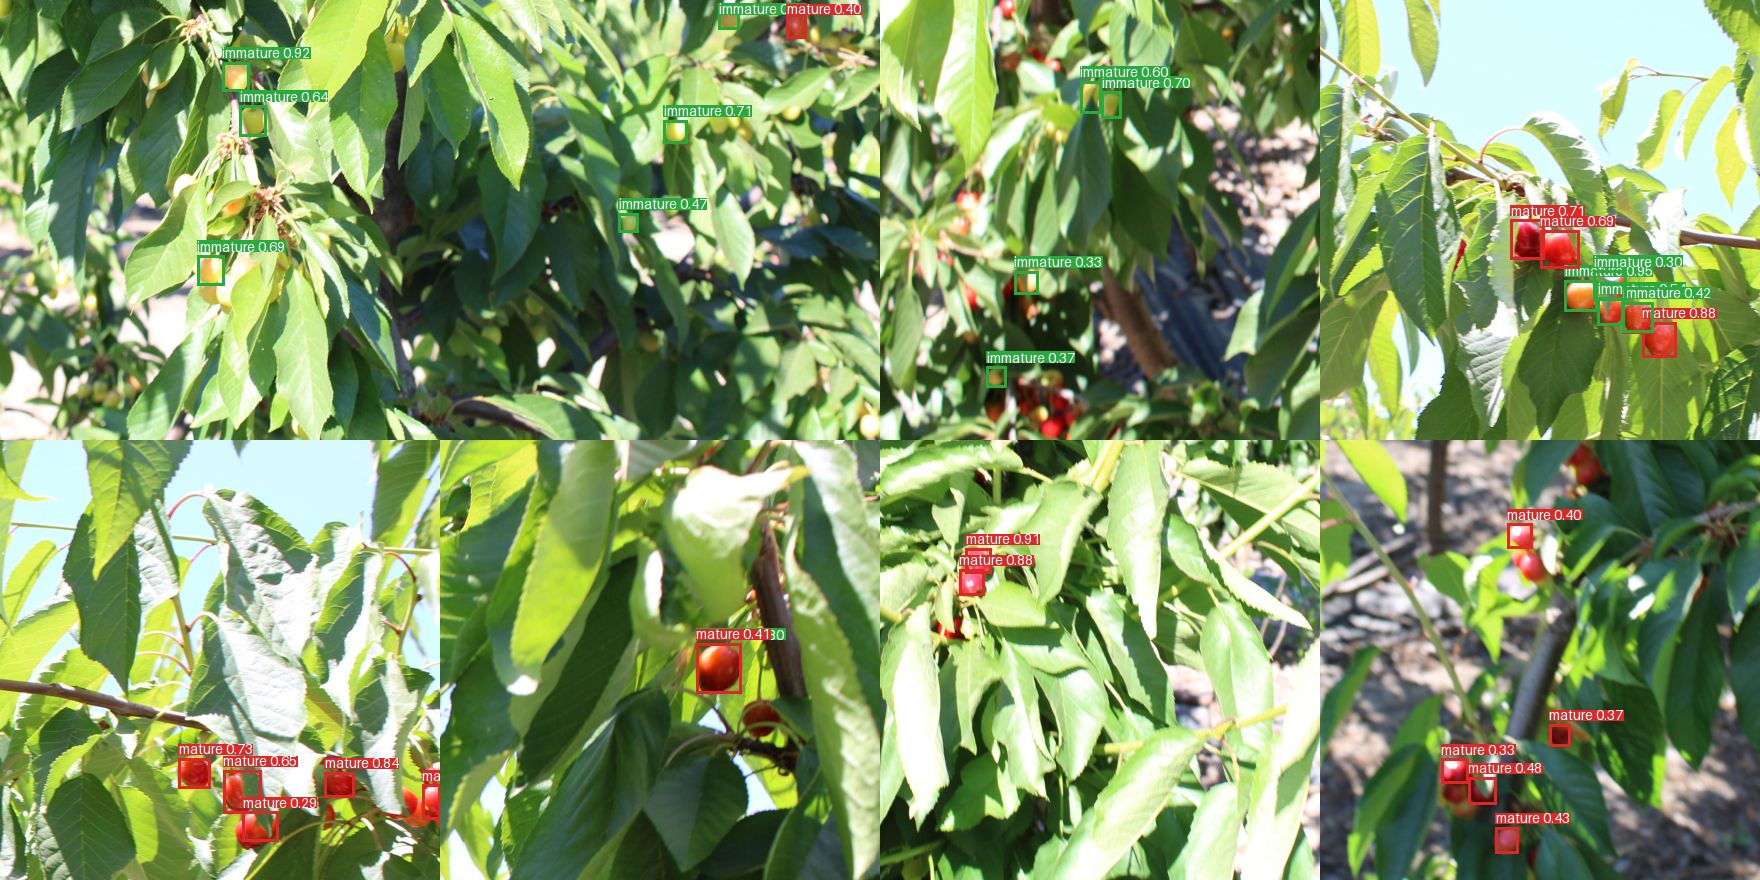

In [5]:
from PIL import ImageFont

COLORS = {"mature": (220, 40, 40), "immature": (40, 170, 60)}
try:
    FONT = ImageFont.load_default(size=14)   # Pillow >= 10.1
except TypeError:
    FONT = ImageFont.load_default()

def draw(ppm_path, dets, size=440):
    im = Image.open(ppm_path).convert("RGB")
    s = size / im.width
    im = im.resize((size, round(im.height * s)))
    d = ImageDraw.Draw(im)
    for label, score, x1, y1, x2, y2 in dets:
        color = COLORS.get(label, (255, 200, 0))
        box = [x1 * s, y1 * s, x2 * s, y2 * s]
        d.rectangle(box, outline=color, width=3)
        text = f"{label} {score:.2f}"
        tx, ty = box[0], max(0, box[1] - 18)
        d.rectangle(d.textbbox((tx, ty), text, font=FONT), fill=color)
        d.text((tx, ty), text, fill="white", font=FONT)
    return im

def grid(tiles, cols=4):
    w, h = tiles[0].size
    rows = (len(tiles) + cols - 1) // cols
    sheet = Image.new("RGB", (cols * w, rows * h), "white")
    for i, t in enumerate(tiles):
        sheet.paste(t, ((i % cols) * w, (i // cols) * h))
    return sheet

sheet = grid([draw(p, detections[p.name]) for p in images])
display(sheet)

## 5. What would the picker do?

Count ripe and unripe cherries per photo: this is the information a picking robot acts on.

In [6]:
print(f"{'image':70s} {'mature':>6s} {'immature':>8s}")
for name, dets in detections.items():
    mature = sum(d[0] == "mature" for d in dets)
    print(f"{name:70s} {mature:6d} {len(dets) - mature:8d}")
total = sum(len(d) for d in detections.values())
print(f"\n{total} cherries in {len(detections)} photos")

image                                                                  mature immature
cherry_N00000_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_11.ppm         0        3
cherry_N00000_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_12.ppm         1        3
cherry_N00358_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_10_10.ppm      0        4
cherry_N00451_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_10_01.ppm      4        4
cherry_N00451_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_10_02.ppm      5        0
cherry_N00483_2021_12_21_H08_50_ripe_fruits_visit2_plot1_row_10_02.ppm      1        1
cherry_N02026_2021_12_21_H08_51_ripe_fruits_visit2_plot1_row_16_11.ppm      2        0
cherry_N02068_2021_12_21_H08_51_ripe_fruits_visit2_plot1_row_16_11.ppm      5        0

33 cherries in 8 photos


## 6. Memory and speed

Each configuration runs as its own process over all photos. **Peak RSS** is the whole process
(code, weights, activations, threads). **Time per image** subtracts a one-image run, so the
one-time model loading is excluded.

- `fp16` (default): fp16 weights for large layers, fp32 for small, precision-sensitive layers;
  fp16 activations.
- `int8`: int8 for the largest layers, fp16 for medium, fp32 for small.
- `fp32`: exact mode, everything fp32.

In [7]:
HELPER = '''
import resource, subprocess, sys
subprocess.run(sys.argv[1:], check=True, stdout=subprocess.DEVNULL)
print(resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss)
'''

def measure(paths, flags):
    cmd = [str(ENGINE), str(MODEL / "model.param"), str(MODEL / "model.bin"),
           *map(str, paths), "--threads", "4", *flags]
    start = time.perf_counter()
    out = subprocess.run([sys.executable, "-c", HELPER, *cmd], check=True,
                         capture_output=True, text=True).stdout
    seconds = time.perf_counter() - start
    rss_mib = int(out) / (1048576 if sys.platform == "darwin" else 1024)
    return seconds, rss_mib

modes = {"fp16 (default)": [], "int8": ["--weights", "int8"],
         "fp32 (exact)": ["--weights", "fp32", "--activations", "fp32", "--input", "fp32"]}
measure(images, [])  # warm-up
print(f"{'mode':16s} {'peak RSS':>10s} {'time / image':>14s}")
for mode, flags in modes.items():
    t_one, _ = measure(images[:1], flags)
    t_all, rss = measure(images, flags)
    per_image = (t_all - t_one) / (len(images) - 1)
    print(f"{mode:16s} {rss:7.1f} MiB {per_image * 1000:10.1f} ms")

mode               peak RSS   time / image
fp16 (default)      13.5 MiB       42.7 ms
int8                11.0 MiB       41.8 ms
fp32 (exact)        22.7 MiB       39.9 ms


## 7. The memory plan

`--stats` prints the planned activation arena and resident weights. `--verbose` prints every
executed op with its output storage type and the live activation memory at that point. Fused
convolutions, row-streamed conv chains (`ConvChain`) and in-place ops all show up here.

In [8]:
plan = subprocess.run([str(ENGINE), str(MODEL / "model.param"), str(MODEL / "model.bin"),
                       str(images[0]), "--stats", "--verbose"],
                      capture_output=True, text=True).stderr
lines = plan.splitlines()
print("\n".join(lines[:12]))
print("...")
print("\n".join(l for l in lines if l.startswith("[stats]")))

op                           type         output            workspace   live_KiB
conv_2+conv_3                ConvChain    [32,160,160]f16      250112       4244
conv_4                       Convolution  [32,160,160]f16      151808       4148
conv_5+conv_6                ConvChain    [16,160,160]f16      260096       2654
cat_0                        Concat       [48,160,160]f16           0       2400
conv_7+conv_8+conv_9         ConvChain    [64,80,80]f16        441600       3631
conv_10+conv_11              ConvChain    [32,80,80]f16        237056       1431
conv_12+conv_13              ConvChain    [32,80,80]f16        237056       1831
cat_1                        Concat       [128,80,80]f16            0       3200
conv_14                      Convolution  [64,80,80]f16        136448       2533
conv_15+conv_16              ConvChain    [128,40,40]f16       619776       1805
conv_17+conv_18              ConvChain    [64,40,40]f16        492800       1881
...
[stats] threads=4 exec_o

## Next steps

- Use your own photos: put JPGs in a folder and run `convert(your_dir, out_dir)`, then `detect(...)`.
- Compare against a reference engine and measure more precisely with `tools/evaluate.py`.
- Tune the precision thresholds with `--fp32-below` and `--int8-min` (see the README).